In [1]:
!nvidia-smi

Fri Oct 23 13:41:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 10.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="I4KiKH43CaE9hpU1jEzh")
project = rf.workspace("mohamed-traore-2ekkp").project("cats-n9b87")
version = project.version(3)
dataset = version.download("yolov11")

from ultralytics import YOLO

print("Начало обучения YOLO11s на 50 эпох...")
model = YOLO("yolo11s.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="cats_yolo11s"
)
print("Обучение завершено!")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Cats-3 in yolov11:: 100%|██████████| 5574/5574 [00:00<00:00, 9928.57it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Начало обучения YOLO11s на 50 эпох...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Cats-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, 

In [6]:
import os
import cv2
from ultralytics import YOLO
from roboflow import Roboflow
import yaml

rf = Roboflow(api_key="I4KiKH43CaE9hpU1jEzh")
dataset = rf.workspace("mohamed-traore-2ekkp").project("cats-n9b87").version(3).download("yolov11")

model = YOLO("runs/detect/cats_yolo11s/weights/best.pt")

print("Финальные метрики на тестовой выборке...")
metrics = model.val(data=f"{dataset.location}/data.yaml", split="test")

print(f"\nРезультаты: ")
print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

!mkdir -p web_cats
!wget -q -O web_cats/cat1.jpg "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=640"
!wget -q -O web_cats/cat2.jpg "https://images.unsplash.com/photo-1519052537078-e6302a4968d4?w=640"
!wget -q -O web_cats/cat3.jpg "https://images.unsplash.com/photo-1495360010541-f48722b34f7d?w=640"

os.makedirs("results", exist_ok=True)
images = sorted([f for f in os.listdir("web_cats") if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

for img_name in images:
    input_path = os.path.join("web_cats", img_name)
    output_path = os.path.join("results", img_name)

    print(f"Обработка: {img_name}...")
    results = model.predict(source=input_path, conf=0.25, save=False)

    annotated_frame = results[0].plot()
    cv2.imwrite(output_path, annotated_frame)

print(f"\nВсе картинки сохранены в папку 'results'")

loading Roboflow workspace...
loading Roboflow project...
Финальные метрики на тестовой выборке...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 9.3±6.5 MB/s, size: 23.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/Cats-3/test/labels... 116 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 116/116 1.2Kit/s 0.1s
val: New cache created: /content/Cats-3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.1it/s 3.7s
                   all        116        116      0.934      0.948      0.968      0.636
Speed: 3.9ms preprocess, 14.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /con

In [7]:
import shutil
import os

shutil.make_archive("results_cats", 'zip', "results")

os.makedirs("plots_only", exist_ok=True)
plot_files = ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png", "labels.jpg"]
for f in plot_files:
    src = os.path.join("runs/detect/cats_yolo11s", f)
    if os.path.exists(src):
        shutil.copy(src, "plots_only")

shutil.make_archive("training_plots", 'zip', "plots_only")

from google.colab import files
files.download("results_cats.zip")
files.download("training_plots.zip")

print("Скачивание запущено")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачивание запущено


Выберите картинку с котами на вашем компьютере:


Saving fotki_ryzhikh_koshek_11.jpg to fotki_ryzhikh_koshek_11.jpg

Обработка файла: fotki_ryzhikh_koshek_11.jpg

image 1/1 /content/fotki_ryzhikh_koshek_11.jpg: 448x640 1 cat, 17.0ms
Speed: 1.7ms preprocess, 17.0ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)
Найдено котов: 1
Результат:


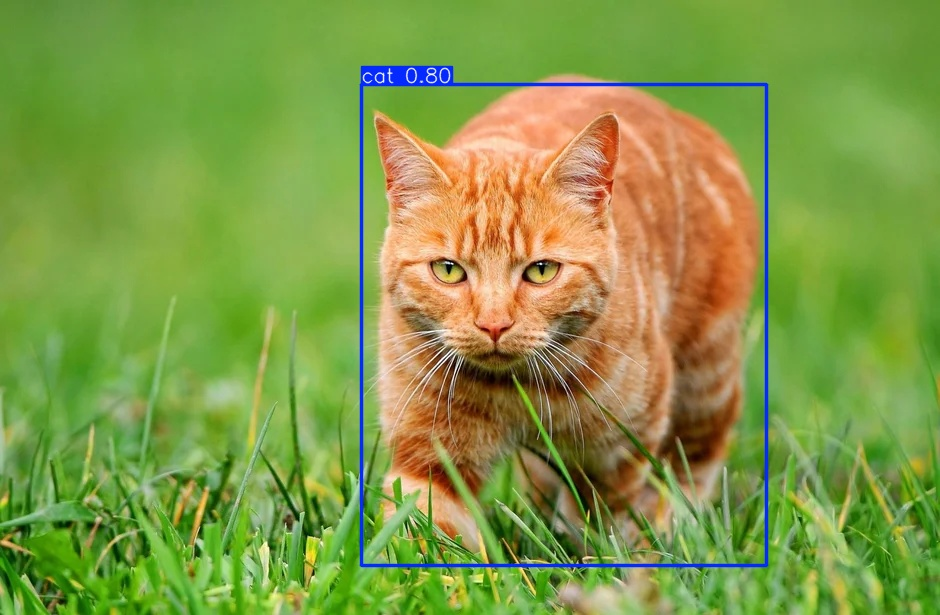

In [11]:
import os
import cv2
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display

print("Выберите картинку с котами на вашем компьютере:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nОбработка файла: {filename}")

    model = YOLO("runs/detect/cats_yolo11s/weights/best.pt")
    results = model.predict(source=filename, conf=0.25, save=False)
    annotated_frame = results[0].plot()
    output_path = f"my_result_{filename}"
    cv2.imwrite(output_path, annotated_frame)
    print(f"Найдено котов: {len(results[0].boxes)}")
    print("Результат:")
    display(Image(filename=output_path))

In [19]:
import os
import cv2
from ultralytics import YOLO

def main():
    model = YOLO("best.pt")

    input_folder = "images"
    output_folder = "results"
    os.makedirs(output_folder, exist_ok=True)

    if not os.path.exists(input_folder):
        print(f"Ошибка: Папка '{input_folder}' не найдена!")
        return

    images = sorted([f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    print(f"Найдено картинок для обработки: {len(images)}")

    for img_name in images:
        input_path = os.path.join(input_folder, img_name)
        output_path = os.path.join(output_folder, img_name)

        print(f"Обработка...")

        results = model.predict(
            source=input_path,
            conf=0.25,
            save=False
        )

        annotated_frame = results[0].plot()
        cv2.imwrite(output_path, annotated_frame)

    print(f"\nВсе обработанные картинки сохранены в папку: {output_folder}")

if __name__ == "__main__":
    main()

Найдено картинок для обработки: 1
Обработка...

image 1/1 /content/images/cat.jpg: 448x640 1 cat, 17.0ms
Speed: 1.9ms preprocess, 17.0ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)

Все обработанные картинки сохранены в папку: results
